# Анализ вовлечённости публикаций Instagram Analytics

Ноутбук разбирает характеристики постов и их `engagement_rate`: сравнивает форматы, строит распределения, проверяет корреляции и нелинейность, оценивает регрессионные модели и сегментирует публикации по метрикам.

> **Ограничения источника:** описание Kaggle утверждает, что данные синтетические; происхождение и лицензия набора в карточке не документированы. В таблице нет авторов публикаций или рёбер между пользователями, поэтому это не сетевой анализ аккаунтов. Формула и единица `engagement_rate` не указаны: не называйте её процентом и не делайте причинных выводов.

Для репрезентативной модели не используйте лайки, комментарии, репосты, сохранения, reach или impressions как предикторы `engagement_rate`, пока не выяснена формула целевой метрики: возможна математическая утечка.

In [27]:
from pathlib import Path
import sys
import warnings

import numpy as np
import pandas as pd
import scipy
from scipy import stats
import matplotlib.pyplot as plt
import seaborn as sns
import statsmodels
import statsmodels.formula.api as smf
from statsmodels.stats.oneway import anova_oneway
from statsmodels.stats.multitest import multipletests
from IPython.display import display

warnings.filterwarnings('ignore', category=FutureWarning)
sns.set_theme(style='whitegrid', context='notebook')
plt.rcParams['figure.figsize'] = (9, 5)

candidates = [
    Path.cwd() / 'dataset' / 'Instagram_Analytics.csv',
    Path.cwd() / 'elective_stat' / 'dataset' / 'Instagram_Analytics.csv',
    Path(__file__).parent / 'dataset' / 'Instagram_Analytics.csv' if '__file__' in globals() else Path('__missing__'),
]
DATA_PATH = next((p for p in candidates if p.exists()), None)
if DATA_PATH is None:
    raise FileNotFoundError('Не найден dataset/Instagram_Analytics.csv. Положите CSV в папку dataset рядом с ноутбуком.')

RESULTS_DIR = DATA_PATH.parent.parent / 'results'
FIGURES_DIR = RESULTS_DIR / 'figures'
FIGURES_DIR.mkdir(parents=True, exist_ok=True)

df = pd.read_csv(DATA_PATH)
print(f'Python {sys.version.split()[0]} | pandas {pd.__version__} | NumPy {np.__version__} | SciPy {scipy.__version__} | statsmodels {statsmodels.__version__}')
print(f'Файл: {DATA_PATH.resolve()} | строк: {len(df):,} | столбцов: {df.shape[1]}')
display(df.head())

Python 3.14.3 | pandas 3.0.6 | NumPy 2.5.4 | SciPy 1.18.1 | statsmodels 0.15.0
Файл: C:\Users\slesa\Desktop\practice\for_private_tests\elective_stat\dataset\Instagram_Analytics.csv | строк: 29,999 | столбцов: 15


,post_id,upload_date,media_type,likes,comments,shares,saves,reach,impressions,caption_length,hashtags_count,followers_gained,traffic_source,engagement_rate,content_category
0,IG0000001,2024-11-30 09:25:22.954916,Reel,31627,7559,4530,6393,615036,1007750,1340,3,899,Home Feed,4.97,Technology
1,IG0000002,2025-08-15 09:25:22.954916,Photo,63206,3490,1680,6809,1237071,1345900,1351,20,805,Hashtags,5.59,Fitness
2,IG0000003,2025-09-11 09:25:22.954916,Reel,94373,3727,1761,8367,1127470,1305369,242,24,758,Reels Feed,8.29,Beauty
3,IG0000004,2025-09-18 09:25:22.954916,Reel,172053,7222,2875,9290,764030,897874,446,11,402,External,21.32,Music
4,IG0000005,2025-03-21 09:25:22.954916,Video,99646,2703,4444,9746,7004,495406,1905,8,155,Profile,23.52,Technology


## 1. Аудит и подготовка

Сначала проверяем фактическое число наблюдений, названия полей, дубликаты и пропуски. ID используются только для контроля строк, а не как числовой признак.

In [28]:
EXPECTED_COLUMNS = {
    'post_id', 'upload_date', 'media_type', 'likes', 'comments', 'shares', 'saves',
    'reach', 'impressions', 'caption_length', 'hashtags_count', 'followers_gained',
    'traffic_source', 'engagement_rate', 'content_category'
}
missing_columns = EXPECTED_COLUMNS - set(df.columns)
extra_columns = set(df.columns) - EXPECTED_COLUMNS
print('Пропущенные ожидаемые поля:', missing_columns)
print('Дополнительные поля:', extra_columns)
print('Дубликатов post_id:', int(df['post_id'].duplicated().sum()) if 'post_id' in df else 'нет поля')
display(df.isna().sum().rename('missing').to_frame())

numeric_cols = ['likes', 'comments', 'shares', 'saves', 'reach', 'impressions', 'caption_length', 'hashtags_count', 'followers_gained', 'engagement_rate']
for col in numeric_cols:
    df[col] = pd.to_numeric(df[col], errors='coerce')
df['upload_date'] = pd.to_datetime(df['upload_date'], errors='coerce')
df['month'] = df['upload_date'].dt.to_period('M').astype(str)

quality = pd.Series({
    'rows': len(df),
    'columns': df.shape[1],
    'duplicate_post_id': int(df['post_id'].duplicated().sum()),
    'missing_engagement_rate': int(df['engagement_rate'].isna().sum()),
    'invalid_dates': int(df['upload_date'].isna().sum()),
    'date_min': df['upload_date'].min(),
    'date_max': df['upload_date'].max(),
})
display(quality.to_frame('value'))
display(df.dtypes.rename('dtype').to_frame())

Пропущенные ожидаемые поля: set()
Дополнительные поля: set()
Дубликатов post_id: 0


,missing
post_id,0
upload_date,0
media_type,0
likes,0
comments,0
shares,0
saves,0
reach,0
impressions,0
caption_length,0


,value
rows,29999
columns,16
duplicate_post_id,0
missing_engagement_rate,0
invalid_dates,0
date_min,2024-11-19 09:25:22.954916
date_max,2025-11-19 09:25:22.954916


,dtype
post_id,str
upload_date,datetime64[us]
media_type,str
likes,int64
comments,int64
shares,int64
saves,int64
reach,int64
impressions,int64
caption_length,int64


## 2. Описательная статистика и визуальная проверка

Изучаем частоты категорий и форму распределения целевой метрики. Из-за очень длинного правого хвоста сравнение средних на исходной шкале может быть чувствительно к выбросам; показываем и медианы, и средние. Выбросы не удаляем без содержательного основания.

Частоты: media_type


,n
media_type,
Carousel,7526
Video,7523
Reel,7515
Photo,7435


Частоты: content_category


,n
content_category,
Photography,3035
Fashion,3034
Technology,3025
Lifestyle,3017
Food,3010
Fitness,3004
Music,3003
Travel,2968
Beauty,2953


Частоты: traffic_source


,n
traffic_source,
Home Feed,5069
Hashtags,5063
Reels Feed,5026
External,5005
Profile,4962
Explore,4874


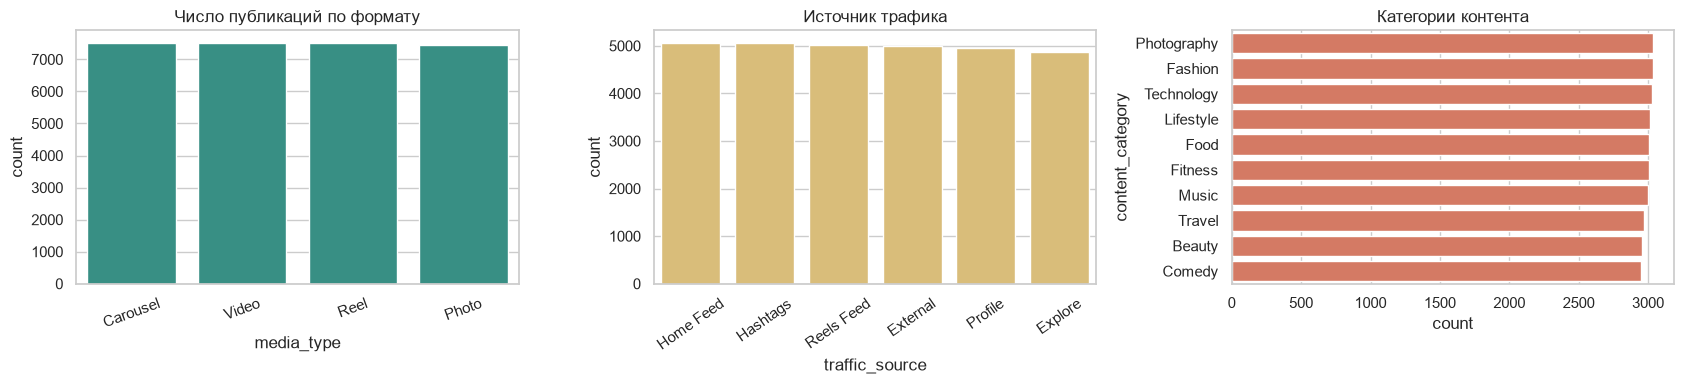

In [29]:
for col in ['media_type', 'content_category', 'traffic_source']:
    print(f'Частоты: {col}')
    display(df[col].value_counts(dropna=False).rename_axis(col).to_frame('n'))

fig, axes = plt.subplots(1, 3, figsize=(17, 4))
sns.countplot(data=df, x='media_type', order=df['media_type'].value_counts().index, ax=axes[0], color='#2A9D8F')
axes[0].set_title('Число публикаций по формату')
axes[0].tick_params(axis='x', rotation=20)
sns.countplot(data=df, x='traffic_source', order=df['traffic_source'].value_counts().index, ax=axes[1], color='#E9C46A')
axes[1].set_title('Источник трафика')
axes[1].tick_params(axis='x', rotation=35)
sns.countplot(data=df, y='content_category', order=df['content_category'].value_counts().index, ax=axes[2], color='#E76F51')
axes[2].set_title('Категории контента')
plt.tight_layout()
plt.show()

,n,mean,median,std,min,max,q1,q3
media_type,,,,,,,,
Carousel,7526,14.323,9.25,23.707,0.29,1027.89,5.270,15.838
Reel,7515,14.541,9.22,26.078,0.38,1250.57,5.235,15.795
Photo,7435,14.191,9.15,21.159,0.12,679.45,5.155,15.420
Video,7523,14.620,9.12,42.711,0.39,3259.82,5.085,15.620


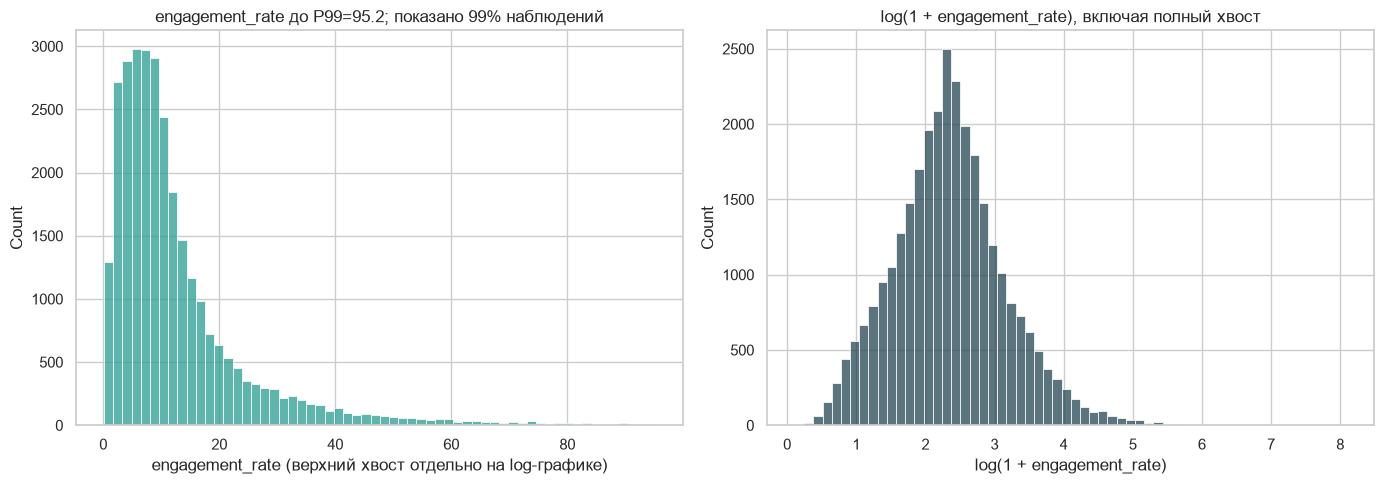

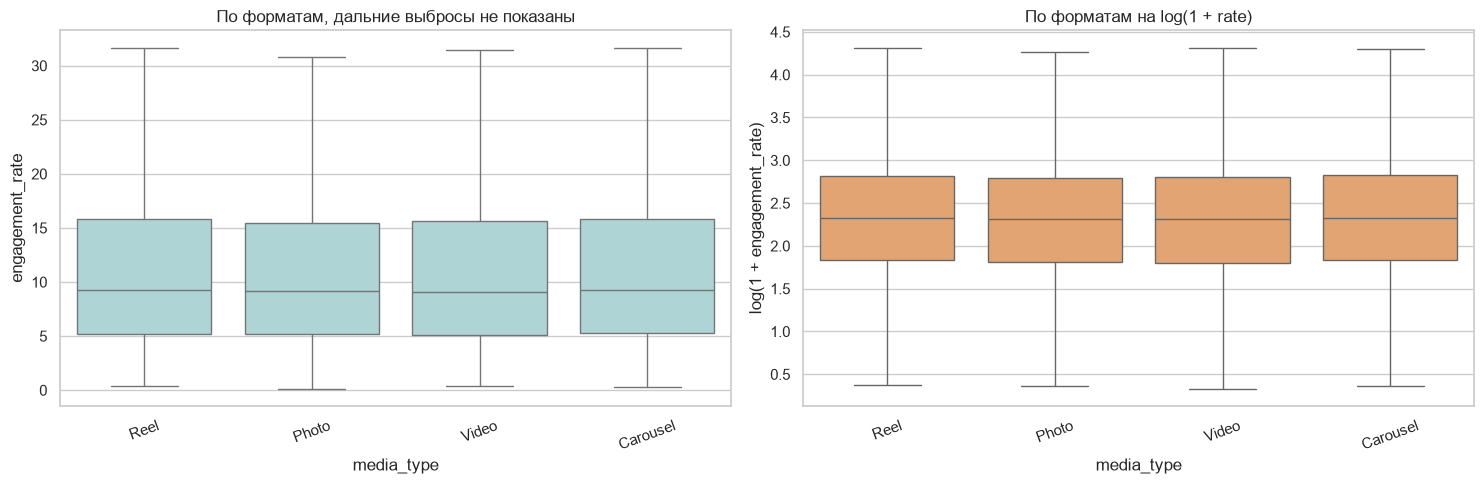

In [30]:
summary = df.groupby('media_type')['engagement_rate'].agg(
    n='count', mean='mean', median='median', std='std', min='min', max='max'
).sort_values('median', ascending=False)
summary['q1'] = df.groupby('media_type')['engagement_rate'].quantile(0.25)
summary['q3'] = df.groupby('media_type')['engagement_rate'].quantile(0.75)
display(summary.round(3))

rate_p99 = df['engagement_rate'].quantile(0.99)
clipped_share = (df['engagement_rate'] > rate_p99).mean()
rate_central = df.loc[df['engagement_rate'] <= rate_p99, 'engagement_rate']
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sns.histplot(x=rate_central, bins=60, ax=axes[0], color='#2A9D8F')
axes[0].set_title(f'engagement_rate до P99={rate_p99:.1f}; показано {1-clipped_share:.0%} наблюдений')
axes[0].set_xlabel('engagement_rate (верхний хвост отдельно на log-графике)')
sns.histplot(x=np.log1p(df['engagement_rate']), bins=60, ax=axes[1], color='#264653')
axes[1].set_title('log(1 + engagement_rate), включая полный хвост')
axes[1].set_xlabel('log(1 + engagement_rate)')
plt.tight_layout()
plt.show()

fig, axes = plt.subplots(1, 2, figsize=(15, 5))
sns.boxplot(data=df, x='media_type', y='engagement_rate', ax=axes[0], color='#A8DADC', showfliers=False)
axes[0].set_title('По форматам, дальние выбросы не показаны')
axes[0].tick_params(axis='x', rotation=20)
sns.boxplot(data=df, x='media_type', y=np.log1p(df['engagement_rate']), ax=axes[1], color='#F4A261', showfliers=False)
axes[1].set_title('По форматам на log(1 + rate)')
axes[1].set_ylabel('log(1 + engagement_rate)')
axes[1].tick_params(axis='x', rotation=20)
plt.tight_layout()
plt.show()

,month,posts,median_rate,mean_rate
0,2024-11,1004,8.845,14.621892
1,2024-12,2532,9.075,13.474052
2,2025-01,2587,9.270,14.752215
3,2025-02,2322,9.175,14.794053
4,2025-03,2499,9.320,15.516475
5,2025-04,2509,9.080,15.128477
6,2025-05,2579,9.360,14.413854
7,2025-06,2494,9.025,13.826427
8,2025-07,2535,9.130,13.569389
9,2025-08,2509,8.950,14.083336


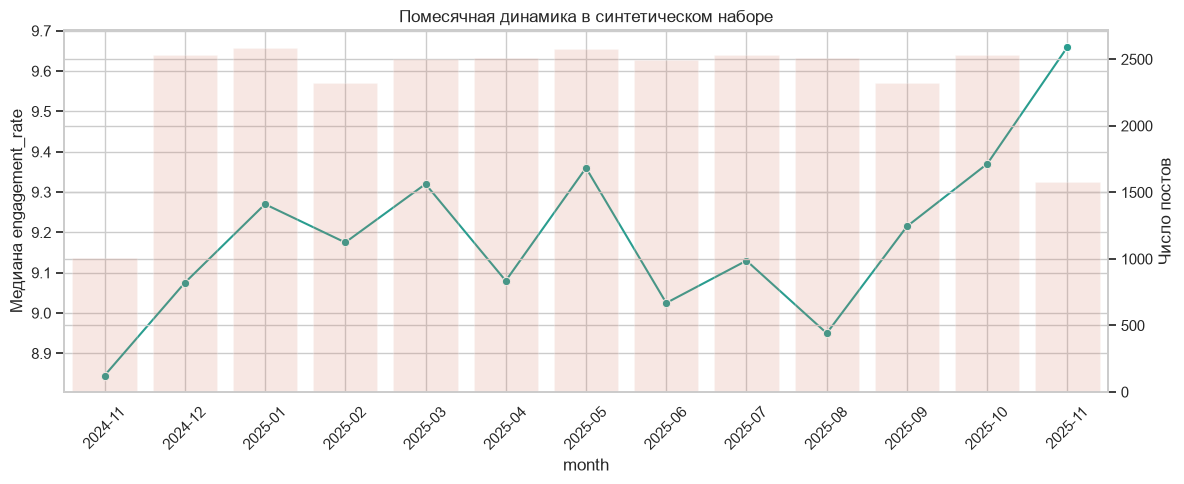

In [31]:
monthly = df.groupby('month').agg(
    posts=('post_id', 'count'),
    median_rate=('engagement_rate', 'median'),
    mean_rate=('engagement_rate', 'mean')
).reset_index()
display(monthly)

fig, ax1 = plt.subplots(figsize=(12, 5))
sns.lineplot(data=monthly, x='month', y='median_rate', marker='o', ax=ax1, color='#2A9D8F')
ax1.set_ylabel('Медиана engagement_rate')
ax1.tick_params(axis='x', rotation=45)
ax2 = ax1.twinx()
sns.barplot(data=monthly, x='month', y='posts', ax=ax2, alpha=0.18, color='#E76F51')
ax2.set_ylabel('Число постов')
ax1.set_title('Помесячная динамика в синтетическом наборе')
plt.tight_layout()
plt.show()

## 3. Сравнение форматов: ANOVA / Welch / Kruskal–Wallis

Сравниваем `log(1 + engagement_rate)` в четырёх независимых группах формата.

- **Levene** проверяет, похожи ли дисперсии групп.
- **Обычная ANOVA** сравнивает средние при предположении одинаковых дисперсий.
- **Welch ANOVA** также сравнивает средние, но устойчивее к неодинаковым дисперсиям; она основной тест в этом разделе.
- **Kruskal–Wallis** сравнивает ранги и служит дополнительной проверкой, менее чувствительной к форме распределения.

H0: средние значения `log(1 + engagement_rate)` одинаковы для всех форматов. H1: хотя бы один формат отличается. p-value не показывает размер различия и сам по себе не доказывает причинность. Для величины эффекта ниже приводится eta-squared.

In [32]:
format_order = sorted(df['media_type'].dropna().unique())
groups_log = [np.log1p(df.loc[df['media_type'] == name, 'engagement_rate'].dropna().to_numpy()) for name in format_order]
levene = stats.levene(*groups_log, center='median')
welch = anova_oneway(groups_log, use_var='unequal', welch_correction=True)
classic = stats.f_oneway(*groups_log)
kruskal = stats.kruskal(*groups_log)
all_log = np.concatenate(groups_log)
grand_mean = all_log.mean()
ss_between = sum(len(group) * (group.mean() - grand_mean) ** 2 for group in groups_log)
eta_squared = ss_between / np.sum((all_log - grand_mean) ** 2)
print(f'Levene: statistic={levene.statistic:.4f}, p={levene.pvalue:.4g}')
print(f'Обычная ANOVA: F={classic.statistic:.4f}, p={classic.pvalue:.4g}, eta-squared={eta_squared:.6f}')
print(f'Welch ANOVA: F={welch.statistic:.4f}, df={welch.df}, p={welch.pvalue:.4g}')
print(f'Kruskal–Wallis: H={kruskal.statistic:.4f}, p={kruskal.pvalue:.4g}')

pairs = []
for i, name_a in enumerate(format_order):
    for name_b in format_order[i + 1:]:
        a = np.log1p(df.loc[df['media_type'] == name_a, 'engagement_rate'].dropna())
        b = np.log1p(df.loc[df['media_type'] == name_b, 'engagement_rate'].dropna())
        test = stats.ttest_ind(a, b, equal_var=False)
        pairs.append({'format_a': name_a, 'format_b': name_b, 't': test.statistic, 'p_raw': test.pvalue})
pairwise = pd.DataFrame(pairs)
pairwise['p_holm'] = multipletests(pairwise['p_raw'], method='holm')[1]
display(pairwise.sort_values('p_holm').round(5))
print('Используйте попарные p_holm только вместе с глобальным тестом и размером эффекта.')

Levene: statistic=0.6805, p=0.5639
Обычная ANOVA: F=0.5720, p=0.6334, eta-squared=0.000057
Welch ANOVA: F=0.5692, df=(3.0, np.float64(16663.127662214993)), p=0.6352
Kruskal–Wallis: H=2.1575, p=0.5404


,format_a,format_b,t,p_raw,p_holm
0,Carousel,Photo,0.74248,0.45781,1.0
1,Carousel,Reel,0.03179,0.97464,1.0
2,Carousel,Video,1.07999,0.28016,1.0
3,Photo,Reel,-0.70692,0.47962,1.0
4,Photo,Video,0.33880,0.73477,1.0
5,Reel,Video,1.04281,0.29705,1.0


Используйте попарные p_holm только вместе с глобальным тестом и размером эффекта.


## 4. Связь метрик и характеристик контента

Корреляции описывают совместное изменение показателей, но не устанавливают причинность. Для `caption_length` и `hashtags_count` используем **Spearman**: он оценивает монотонную связь по рангам и меньше зависит от выбросов. **Pearson** приведён для сравнения линейной связи.

Корреляции с likes/reach/impressions — только описательные: формула `engagement_rate` неизвестна и может уже включать эти метрики. Поэтому связь с ними может быть математически встроена в целевую метрику.

Проверяется несколько пар, поэтому малые p-values счётчиков могут быть следствием большого N и множественных проверок. Смотрите на размер rho, а не только на p-value; для текста/хэштегов ключевой вопрос — насколько велик сам коэффициент.

,x,y,n,spearman_rho,spearman_p,pearson_r,pearson_p
0,reach,engagement_rate,29999,-0.62971,<0.0001,-0.33869,<0.0001
1,impressions,engagement_rate,29999,-0.65057,<0.0001,-0.36612,<0.0001
2,likes,engagement_rate,29999,0.70170,<0.0001,0.24297,<0.0001
3,comments,engagement_rate,29999,0.03276,<0.0001,0.01880,0.0011
4,caption_length,engagement_rate,29999,0.00452,0.4342,0.01339,0.0204
5,hashtags_count,engagement_rate,29999,0.00405,0.4832,0.00015,0.9796


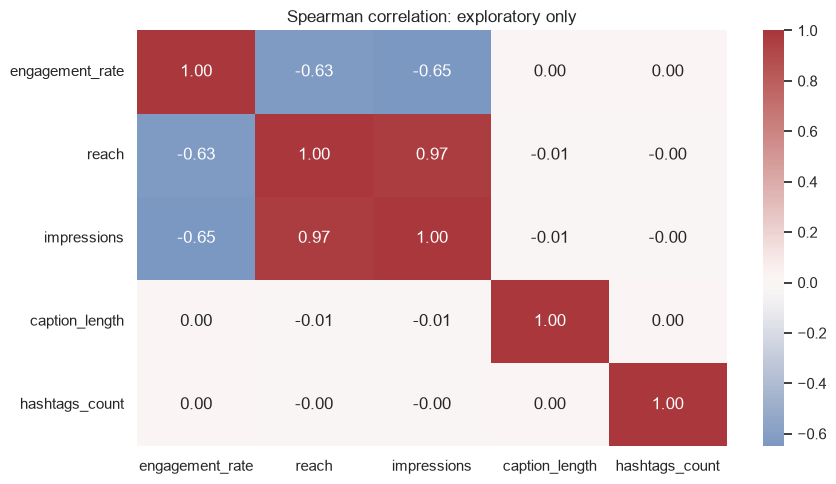

In [33]:
pairs_to_check = [
    ('reach', 'engagement_rate'), ('impressions', 'engagement_rate'),
    ('likes', 'engagement_rate'), ('comments', 'engagement_rate'),
    ('caption_length', 'engagement_rate'), ('hashtags_count', 'engagement_rate')
]
corr_rows = []
for x, y in pairs_to_check:
    clean = df[[x, y]].dropna()
    sp = stats.spearmanr(clean[x], clean[y])
    pe = stats.pearsonr(clean[x], clean[y])
    corr_rows.append({'x': x, 'y': y, 'n': len(clean), 'spearman_rho': sp.statistic, 'spearman_p': sp.pvalue, 'pearson_r': pe.statistic, 'pearson_p': pe.pvalue})
corr_table = pd.DataFrame(corr_rows)
corr_display = corr_table.copy()
for p_col in ['spearman_p', 'pearson_p']:
    corr_display[p_col] = corr_display[p_col].map(lambda value: '<0.0001' if value < 0.0001 else f'{value:.4f}')
display(corr_display.round({'spearman_rho': 5, 'pearson_r': 5}))

plot_cols = ['engagement_rate', 'reach', 'impressions', 'caption_length', 'hashtags_count']
corr_matrix = df[plot_cols].corr(method='spearman')
sns.heatmap(corr_matrix, annot=True, cmap='vlag', center=0, fmt='.2f')
plt.title('Spearman correlation: exploratory only')
plt.tight_layout()
plt.show()

### Нелинейность: зачем добавляются квадратичные члены

Обычная корреляция и прямая линия не выявляют U-образную или перевёрнутую U-образную зависимость. Поэтому для двух заранее выбранных признаков (`caption_length`, `hashtags_count`) сравниваем линейную форму с моделью, где добавлены квадраты признаков. Признаки сначала стандартизируются, чтобы квадраты имели сопоставимый масштаб. Wald-тест совместно проверяет, равны ли оба квадратичных коэффициента нулю; HC3 — вариант стандартных ошибок, устойчивый к неодинаковому разбросу остатков. Это дополнительная проверка, а не доказательство причинного эффекта.

H0: оба квадратичных члена равны нулю
Wald test: statistic=2.8570, p=0.2397


,coef,std err,z,P>|z|,[0.025,0.975]
Intercept,2.3497,0.012,197.981,0.000,2.326,2.373
C(media_type)[T.Photo],-0.0097,0.013,-0.741,0.459,-0.036,0.016
C(media_type)[T.Reel],-0.0003,0.013,-0.023,0.982,-0.026,0.025
C(media_type)[T.Video],-0.0143,0.013,-1.087,0.277,-0.040,0.012
caption_length_z,0.0061,0.005,1.303,0.193,-0.003,0.015
caption_length_z2,-0.0031,0.005,-0.596,0.551,-0.013,0.007
hashtags_count_z,0.0035,0.005,0.756,0.450,-0.006,0.013
hashtags_count_z2,0.0083,0.005,1.576,0.115,-0.002,0.019


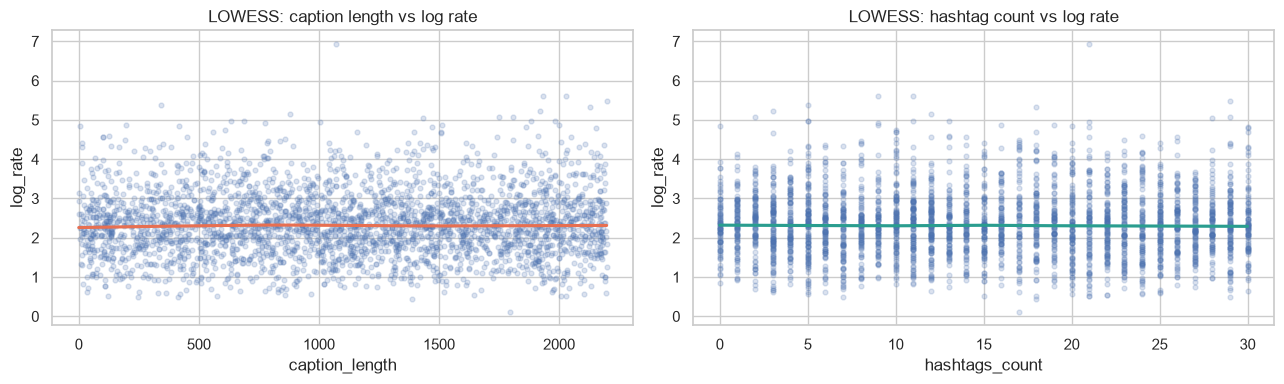

In [41]:
import statsmodels.formula.api as smf

nonlinear = df[['caption_length', 'hashtags_count', 'engagement_rate', 'media_type']].dropna().copy()
nonlinear['log_rate'] = np.log1p(nonlinear['engagement_rate'])

# Стандартизация делает квадратичные термины численно устойчивее.
for col in ['caption_length', 'hashtags_count']:
    nonlinear[col + '_z'] = (nonlinear[col] - nonlinear[col].mean()) / nonlinear[col].std(ddof=0)
    nonlinear[col + '_z2'] = nonlinear[col + '_z'] ** 2

# HC3 корректирует стандартные ошибки при неодинаковом разбросе остатков.
quadratic_fit = smf.ols(
    'log_rate ~ caption_length_z + caption_length_z2 + hashtags_count_z + hashtags_count_z2 + C(media_type)',
    data=nonlinear
).fit(cov_type='HC3')
nonlinear_test = quadratic_fit.wald_test('caption_length_z2 = 0, hashtags_count_z2 = 0', scalar=True)
print('H0: оба квадратичных члена равны нулю')
print(f'Wald test: statistic={float(nonlinear_test.statistic):.4f}, p={float(nonlinear_test.pvalue):.4g}')
display(quadratic_fit.summary().tables[1])

plot_data = nonlinear.sample(min(3000, len(nonlinear)), random_state=42)
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
sns.regplot(data=plot_data, x='caption_length', y='log_rate', lowess=True, scatter_kws={'alpha': 0.2, 's': 12}, line_kws={'color': '#E76F51'}, ax=axes[0])
axes[0].set_title('LOWESS: caption length vs log rate')
sns.regplot(data=plot_data, x='hashtags_count', y='log_rate', lowess=True, scatter_kws={'alpha': 0.2, 's': 12}, line_kws={'color': '#2A9D8F'}, ax=axes[1])
axes[1].set_title('LOWESS: hashtag count vs log rate')
plt.tight_layout()
plt.show()

## 5. Проверка независимости: формат и категория вовлечённости

Чтобы согласовать непрерывную метрику с темой χ² из электива, разбиваем её на терцили. Основной вывод о форматах делаем по ANOVA/Welch; χ² — наглядное дополнительное сравнение распределений категорий.

Observed table:


engagement_level,Low,Medium,High
media_type,,,
Carousel,2466,2553,2507
Photo,2505,2469,2461
Reel,2492,2491,2532
Video,2555,2473,2495


Chi-square=3.7710, df=6, p=0.70763, Cramér V=0.00793
Min expected count=2474.95


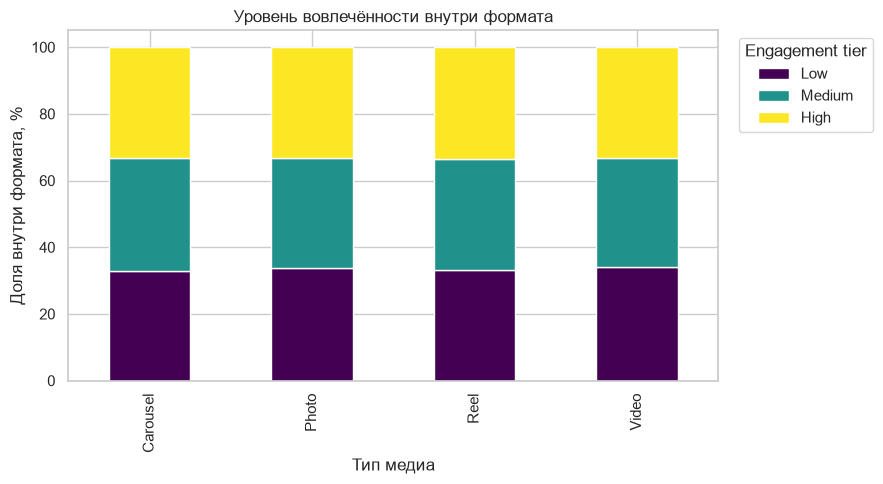

In [35]:
df['engagement_level'] = pd.qcut(df['engagement_rate'], q=3, labels=['Low', 'Medium', 'High'], duplicates='drop')
table = pd.crosstab(df['media_type'], df['engagement_level'])
chi2, p_value, dof, expected = stats.chi2_contingency(table)
n = table.to_numpy().sum()
r, k = table.shape
cramers_v = np.sqrt(chi2 / (n * min(r - 1, k - 1)))
print('Observed table:')
display(table)
print(f'Chi-square={chi2:.4f}, df={dof}, p={p_value:.5g}, Cramér V={cramers_v:.5f}')
print(f'Min expected count={expected.min():.2f}')

row_pct = table.div(table.sum(axis=1), axis=0) * 100
ax = row_pct.plot(kind='bar', stacked=True, figsize=(9, 5), colormap='viridis')
ax.set_ylabel('Доля внутри формата, %')
ax.set_xlabel('Тип медиа')
ax.set_title('Уровень вовлечённости внутри формата')
ax.legend(title='Engagement tier', bbox_to_anchor=(1.02, 1), loc='upper left')
plt.tight_layout()
plt.show()

## 6. Прогноз engagement_rate: baseline, линейная модель и Random Forest

Задача — проверить, можно ли предсказать показатель по характеристикам поста. Это оценка прогноза, не причинного влияния.

В качестве признаков используются доступные характеристики: формат, категория, источник трафика, длина подписи, число хэштегов и месяц. Реакции и охват исключены: при неизвестной формуле `engagement_rate` они могут быть частью ответа, то есть создать утечку.

Данные сортируются по времени. Последняя часть дат используется как тест; один календарный день целиком попадает только в train или только в test. One-Hot Encoding и масштабирование выполняются внутри pipeline, обучаемого только на train. Сравниваются медианный baseline, линейная регрессия и Random Forest.

In [42]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.dummy import DummyRegressor
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error

model_df = df.dropna(subset=['upload_date', 'engagement_rate']).sort_values('upload_date').copy()
model_df['month_num'] = model_df['upload_date'].dt.month
feature_cols = ['caption_length', 'hashtags_count', 'month_num', 'media_type', 'content_category', 'traffic_source']
numeric_features = ['caption_length', 'hashtags_count', 'month_num']
categorical_features = ['media_type', 'content_category', 'traffic_source']

# Отделяем последние 20% уникальных дат; не делим один день между train и test.
unique_dates = pd.Index(model_df['upload_date'].dt.normalize().unique()).sort_values()
cutoff_date = unique_dates[int(len(unique_dates) * 0.8)]
train = model_df.loc[model_df['upload_date'].dt.normalize() < cutoff_date]
test = model_df.loc[model_df['upload_date'].dt.normalize() >= cutoff_date]
X_train, X_test = train[feature_cols], test[feature_cols]

# Цель логарифмируем для обучения; метрики ниже считаем также после обратного преобразования.
y_train = np.log1p(train['engagement_rate'])
y_test = test['engagement_rate'].to_numpy()

# Пропуски/масштаб/категории обрабатываются внутри pipeline, чтобы не обучаться на test.
preprocessor = ColumnTransformer([
    ('num', Pipeline([('imputer', SimpleImputer(strategy='median')), ('scale', StandardScaler())]), numeric_features),
    ('cat', Pipeline([('imputer', SimpleImputer(strategy='most_frequent')), ('onehot', OneHotEncoder(handle_unknown='ignore'))]), categorical_features),
])
models = {
    'Baseline median': DummyRegressor(strategy='median'),
    'Linear regression': LinearRegression(),
    'Random forest': RandomForestRegressor(n_estimators=250, min_samples_leaf=5, max_features=0.8, n_jobs=-1, random_state=42),
}
predictions = {}
model_rows = []
for name, estimator in models.items():
    pipe = Pipeline([('prep', preprocessor), ('model', estimator)])
    pipe.fit(X_train, y_train)
    pred_log = pipe.predict(X_test)
    pred = np.maximum(0, np.expm1(pred_log))
    predictions[name] = pred
    model_rows.append({
        'model': name,
        'R2_original_scale': r2_score(y_test, pred),
        'MAE_original_scale': mean_absolute_error(y_test, pred),
        'RMSE_original_scale': np.sqrt(mean_squared_error(y_test, pred)),
        'MAE_log_scale': mean_absolute_error(np.log1p(y_test), pred_log),
    })
model_results = pd.DataFrame(model_rows).sort_values('MAE_original_scale')
display(model_results.round(4))
print(f'Date cutoff: {cutoff_date.date()} | train posts: {len(train):,} | test posts: {len(test):,}')

,model,R2_original_scale,MAE_original_scale,RMSE_original_scale,MAE_log_scale
0,Baseline median,-0.0752,9.2988,20.3248,0.6304
1,Linear regression,-0.0731,9.3007,20.3043,0.6305
2,Random forest,-0.0756,9.3809,20.3284,0.6384


Date cutoff: 2025-09-07 | train posts: 24,047 | test posts: 5,952


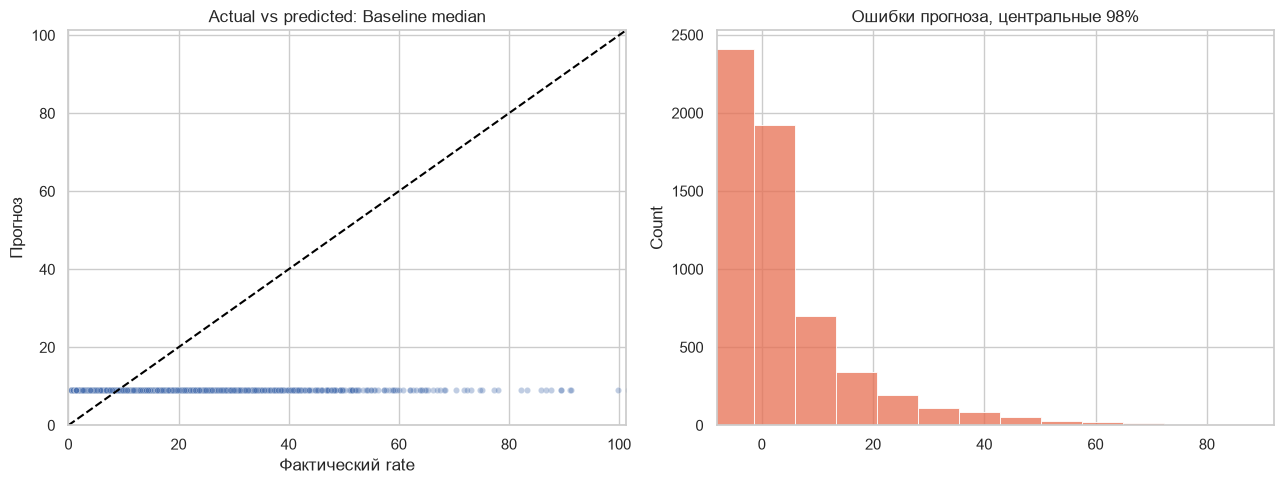

Хронологическое разделение: 2024-11-19 09:25:22.954916 — 2025-09-06 09:25:22.954916 | test: 2025-09-07 09:25:22.954916 — 2025-11-19 09:25:22.954916
Лучшая по MAE модель: Baseline median


In [37]:
best_name = model_results.iloc[0]['model']
best_pred = predictions[best_name]
sample_idx = np.random.default_rng(42).choice(len(y_test), size=min(2500, len(y_test)), replace=False)
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
sns.scatterplot(x=y_test[sample_idx], y=best_pred[sample_idx], alpha=0.35, s=20, ax=axes[0])
upper = np.quantile(y_test, 0.99)
axes[0].plot([0, upper], [0, upper], '--', color='black')
axes[0].set_xlim(0, upper)
axes[0].set_ylim(0, upper)
axes[0].set_title(f'Actual vs predicted: {best_name}')
axes[0].set_xlabel('Фактический rate')
axes[0].set_ylabel('Прогноз')
sns.histplot(y_test - best_pred, bins=50, ax=axes[1], color='#E76F51')
axes[1].set_xlim(np.quantile(y_test - best_pred, 0.01), np.quantile(y_test - best_pred, 0.99))
axes[1].set_title('Ошибки прогноза, центральные 98%')
plt.tight_layout()
plt.show()
print('Хронологическое разделение:', train['upload_date'].min(), '—', train['upload_date'].max(), '| test:', test['upload_date'].min(), '—', test['upload_date'].max())
print('Лучшая по MAE модель:', best_name)

## 7. Кластеризация публикаций по метрикам вовлечённости

K-Means группирует посты по похожим значениям likes/comments/shares/saves/reach/impressions. Все эти поля логарифмируются (`log1p`) из-за больших диапазонов, затем стандартизируются, чтобы крупные единицы измерения не доминировали.

Пробуем `k=2…6`; silhouette — ориентир компактности и разделённости групп, а не доказательство «правильных» классов. PCA-проекция нужна только для наглядного рисунка. Это сегментация данного набора, а не классификатор вирусности и не доказательство естественных типов публикаций. Кластеры интерпретируются по таблице медианных профилей.

,k,inertia,silhouette
0,2,141472.4247,0.2753
1,3,125233.1578,0.2340
2,4,110450.2283,0.2320
3,5,96735.1314,0.2413
4,6,84060.1641,0.2554


Chosen k by silhouette (exploratory): 2


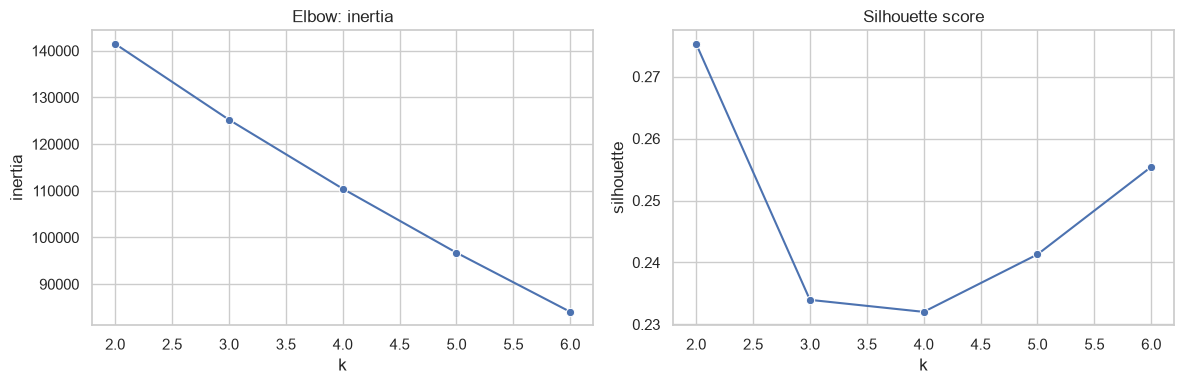

,posts,median_rate,median_likes,median_comments,median_shares,median_reach
cluster,,,,,,
1,7925,23.19,100681.0,5040.0,2529.0,266823.0
0,22074,7.53,99143.0,5045.5,2486.5,1256767.0


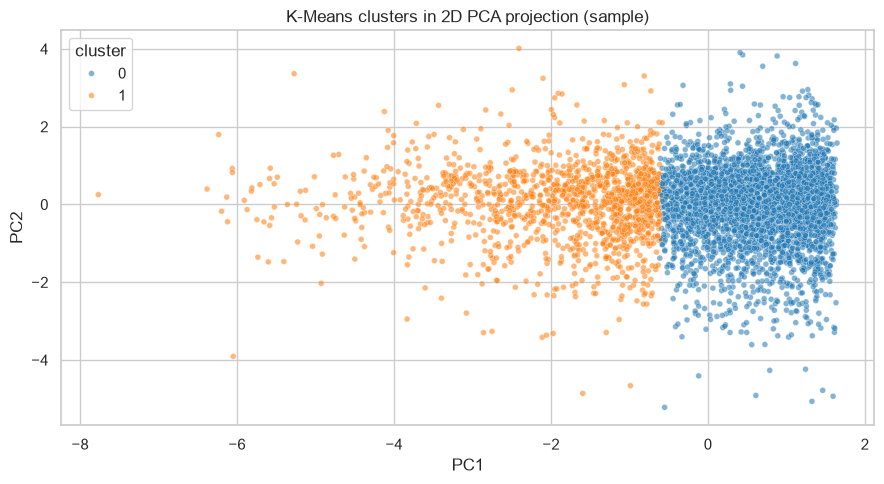

In [43]:
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_score

cluster_features = ['likes', 'comments', 'shares', 'saves', 'reach', 'impressions']
cluster_data = df[cluster_features].apply(pd.to_numeric, errors='coerce').fillna(0).clip(lower=0)
# log1p уменьшает перекос счётчиков; StandardScaler приводит признаки к общей шкале.
X_cluster = np.log1p(cluster_data)
X_scaled = StandardScaler().fit_transform(X_cluster)

# Проверяем небольшое число вариантов k; silhouette используется как ориентир.
silhouette_rows = []
for k in range(2, 7):
    km = KMeans(n_clusters=k, n_init=10, random_state=42)
    labels = km.fit_predict(X_scaled)
    silhouette_rows.append({'k': k, 'inertia': km.inertia_, 'silhouette': silhouette_score(X_scaled, labels, sample_size=min(5000, len(labels)), random_state=42)})
silhouette_table = pd.DataFrame(silhouette_rows)
display(silhouette_table.round(4))
best_k = int(silhouette_table.loc[silhouette_table['silhouette'].idxmax(), 'k'])
km = KMeans(n_clusters=best_k, n_init=10, random_state=42)
df['cluster'] = km.fit_predict(X_scaled)
print('Chosen k by silhouette (exploratory):', best_k)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.lineplot(data=silhouette_table, x='k', y='inertia', marker='o', ax=axes[0])
axes[0].set_title('Elbow: inertia')
sns.lineplot(data=silhouette_table, x='k', y='silhouette', marker='o', ax=axes[1])
axes[1].set_title('Silhouette score')
plt.tight_layout()
plt.show()

cluster_profile = df.groupby('cluster').agg(
    posts=('post_id', 'count'),
    median_rate=('engagement_rate', 'median'),
    median_likes=('likes', 'median'),
    median_comments=('comments', 'median'),
    median_shares=('shares', 'median'),
    median_reach=('reach', 'median'),
).sort_values('median_rate', ascending=False)
display(cluster_profile.round(2))

# Сжимаем 6 признаков в 2 координаты только для графика; кластеры уже рассчитаны выше.
pca = PCA(n_components=2, random_state=42)
coords = pca.fit_transform(X_scaled)
pca_plot = pd.DataFrame({'PC1': coords[:, 0], 'PC2': coords[:, 1], 'cluster': df['cluster'].astype(str)})
pca_plot = pca_plot.sample(min(5000, len(pca_plot)), random_state=42)
sns.scatterplot(data=pca_plot, x='PC1', y='PC2', hue='cluster', palette='tab10', alpha=0.55, s=18)
plt.title('K-Means clusters in 2D PCA projection (sample)')
plt.tight_layout()
plt.show()

## 8. Краткие результаты для презентации

Сформируйте выводы только после просмотра всех ячеек. Не интерпретируйте синтетические закономерности как реальное поведение аудитории; `engagement_rate` имеет неизвестное определение, а высокий R² не доказывает причинность.

In [44]:
print(f'1. В анализе {len(df):,} постов, {len(EXPECTED_COLUMNS)} исходных полей; пропусков: {int(df[list(EXPECTED_COLUMNS)].isna().sum().sum())}.')
print(f'2. Медиана engagement_rate={df.engagement_rate.median():.2f}, среднее={df.engagement_rate.mean():.2f}, максимум={df.engagement_rate.max():.2f}.')
print(f'3. Welch ANOVA p={welch.pvalue:.4g}; eta-squared={eta_squared:.6f}; Kruskal–Wallis p={kruskal.pvalue:.4g}.')
print(f'4. Тип медиа × терциль rate: chi-square p={p_value:.4g}, Cramér V={cramers_v:.4f}.')
caption_rho = corr_table.loc[corr_table['x'] == 'caption_length', 'spearman_rho'].iloc[0]
hashtag_rho = corr_table.loc[corr_table['x'] == 'hashtags_count', 'spearman_rho'].iloc[0]
print(f'5. Spearman rho: caption_length={caption_rho:.4f}; hashtags_count={hashtag_rho:.4f}.')
print(f'6. Лучшая по MAE модель: {best_name}; R2={model_results.iloc[0]["R2_original_scale"]:.4f}, MAE={model_results.iloc[0]["MAE_original_scale"]:.2f}.')
silhouette_best = silhouette_table.loc[silhouette_table['k'] == best_k, 'silhouette'].iloc[0]
print(f'7. Кластеризация: k={best_k}; silhouette={silhouette_best:.4f}. Названия сегментов описывайте по профилям, не как гарантированную вирусность.')

1. В анализе 29,999 постов, 15 исходных полей; пропусков: 0.
2. Медиана engagement_rate=9.19, среднее=14.42, максимум=3259.82.
3. Welch ANOVA p=0.6352; eta-squared=0.000057; Kruskal–Wallis p=0.5404.
4. Тип медиа × терциль rate: chi-square p=0.7076, Cramér V=0.0079.
5. Spearman rho: caption_length=0.0045; hashtags_count=0.0040.
6. Лучшая по MAE модель: Baseline median; R2=-0.0752, MAE=9.30.
7. Кластеризация: k=2; silhouette=0.2753. Названия сегментов описывайте по профилям, не как гарантированную вирусность.


In [45]:
RESULTS_DIR = DATA_PATH.parent.parent / 'results'
FIGURES_DIR = RESULTS_DIR / 'figures'
FIGURES_DIR.mkdir(parents=True, exist_ok=True)
summary.to_csv(RESULTS_DIR / 'engagement_by_media_type.csv')
monthly.to_csv(RESULTS_DIR / 'monthly_summary.csv', index=False)
corr_table.to_csv(RESULTS_DIR / 'spearman_correlations.csv', index=False)
table.to_csv(RESULTS_DIR / 'media_type_by_engagement_tercile.csv')
model_results.to_csv(RESULTS_DIR / 'model_metrics.csv', index=False)
cluster_profile.to_csv(RESULTS_DIR / 'cluster_profiles.csv')

# Recreate selected plots here so the presentation-ready PNGs are saved explicitly.
fig, ax = plt.subplots(figsize=(8, 5))
sns.countplot(data=df, x='media_type', order=df['media_type'].value_counts().index, ax=ax, color='#2A9D8F')
ax.set_title('Число публикаций по формату')
ax.tick_params(axis='x', rotation=20)
fig.savefig(FIGURES_DIR / '01_media_type_counts.png', dpi=180, bbox_inches='tight')
plt.close(fig)

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
sns.histplot(df.loc[df['engagement_rate'] <= rate_p99, 'engagement_rate'], bins=60, ax=axes[0], color='#2A9D8F')
axes[0].set_title(f'engagement_rate до P99={rate_p99:.1f}; 99% наблюдений')
sns.histplot(np.log1p(df['engagement_rate']), bins=60, ax=axes[1], color='#264653')
axes[1].set_title('log(1 + engagement_rate), весь диапазон')
fig.savefig(FIGURES_DIR / '02_engagement_distributions.png', dpi=180, bbox_inches='tight')
plt.close(fig)

fig, ax = plt.subplots(figsize=(8, 5))
sns.boxplot(data=df, x='media_type', y=np.log1p(df['engagement_rate']), ax=ax, color='#F4A261', showfliers=False)
ax.set_title('Вовлечённость по формату, логарифмическая шкала')
ax.set_ylabel('log(1 + engagement_rate)')
fig.savefig(FIGURES_DIR / '03_engagement_boxplot.png', dpi=180, bbox_inches='tight')
plt.close(fig)

fig, ax1 = plt.subplots(figsize=(11, 5))
sns.lineplot(data=monthly, x='month', y='median_rate', marker='o', ax=ax1, color='#2A9D8F')
ax1.set_ylabel('Медиана engagement_rate')
ax1.tick_params(axis='x', rotation=45)
ax2 = ax1.twinx()
sns.barplot(data=monthly, x='month', y='posts', ax=ax2, alpha=0.18, color='#E76F51')
ax2.set_ylabel('Число постов')
ax1.set_title('Помесячная динамика')
fig.savefig(FIGURES_DIR / '04_monthly_trend.png', dpi=180, bbox_inches='tight')
plt.close(fig)

fig, ax = plt.subplots(figsize=(7, 5))
row_pct.plot(kind='bar', stacked=True, ax=ax, colormap='viridis')
ax.set_ylabel('Доля внутри формата, %')
ax.set_xlabel('Тип медиа')
ax.set_title('Уровень вовлечённости внутри формата')
ax.legend(title='Engagement tier', bbox_to_anchor=(1.02, 1), loc='upper left')
fig.savefig(FIGURES_DIR / '05_format_by_engagement_tier.png', dpi=180, bbox_inches='tight')
plt.close(fig)

fig, ax = plt.subplots(figsize=(7, 6))
sns.heatmap(corr_matrix, annot=True, cmap='vlag', center=0, fmt='.2f', ax=ax)
ax.set_title('Корреляции Спирмена, исследовательский анализ')
fig.savefig(FIGURES_DIR / '06_spearman_heatmap.png', dpi=180, bbox_inches='tight')
plt.close(fig)

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
sns.scatterplot(x=y_test[sample_idx], y=best_pred[sample_idx], alpha=0.35, s=18, ax=axes[0])
upper = np.quantile(y_test, 0.99)
axes[0].plot([0, upper], [0, upper], '--', color='black')
axes[0].set_xlim(0, upper)
axes[0].set_ylim(0, upper)
axes[0].set_title(f'Actual vs predicted: {best_name}')
sns.histplot(y_test - best_pred, bins=50, ax=axes[1], color='#E76F51')
axes[1].set_xlim(np.quantile(y_test - best_pred, 0.01), np.quantile(y_test - best_pred, 0.99))
axes[1].set_title('Ошибки прогноза, центральные 98%')
fig.savefig(FIGURES_DIR / '07_model_predictions.png', dpi=180, bbox_inches='tight')
plt.close(fig)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.lineplot(data=silhouette_table, x='k', y='inertia', marker='o', ax=axes[0])
axes[0].set_title('Elbow: inertia')
sns.lineplot(data=silhouette_table, x='k', y='silhouette', marker='o', ax=axes[1])
axes[1].set_title('Silhouette score')
fig.savefig(FIGURES_DIR / '08_cluster_selection.png', dpi=180, bbox_inches='tight')
plt.close(fig)

fig, ax = plt.subplots(figsize=(8, 6))
sns.scatterplot(data=pca_plot, x='PC1', y='PC2', hue='cluster', palette='tab10', alpha=0.55, s=18, ax=ax)
ax.set_title('K-Means clusters, PCA projection (sample)')
fig.savefig(FIGURES_DIR / '09_kmeans_pca.png', dpi=180, bbox_inches='tight')
plt.close(fig)

saved_pngs = sorted(FIGURES_DIR.glob('*.png'))
print(f'Таблицы и метрики сохранены в {RESULTS_DIR.resolve()}')
print(f'Графики сохранены в {FIGURES_DIR.resolve()} ({len(saved_pngs)} PNG)')

Таблицы и метрики сохранены в C:\Users\slesa\Desktop\practice\for_private_tests\elective_stat\results
Графики сохранены в C:\Users\slesa\Desktop\practice\for_private_tests\elective_stat\results\figures (9 PNG)
